# Radiation-acoustic waves in every trapping regime

A small (1e-6) sound wave in a uniform periodic gas + radiation box (`decks/wave_cart.athinput`,
64 x 4 cells, two periods, cfl 0.3), started on the exact eigenmode. The phase speed and the damping
rate of the k = 1 mode are fitted (drho and dv together) and compared with the analytic root of
the linear gas + moment system (`vett.radwave_root`: the comoving face flux and the `vet_sc`
closure of the code's rays). $x = \tau_{\rm cell}\,c_{\rm eq}/c$ is the grid-scale trapping
parameter: thin (x = 0.01), intermediate (0.1, 1) and trapped (100).
`thin_old` is the thin case without `hydro/rad_signal_speed_diff`, for the time-step gain.

Criterion: per case $|c_{\rm ph}/c_{\rm ph,exact}-1| \le 3\times10^{-3}$, damping error
$\le 5\times10^{-3}$ per radian, no growth; dt gain within 2 % of 2.77; no `CLEAN WARNING`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TEST = 'radwave'
res = nb.suite(TEST, EXE, WORK, THREADS)

loading the existing run runs/radwave


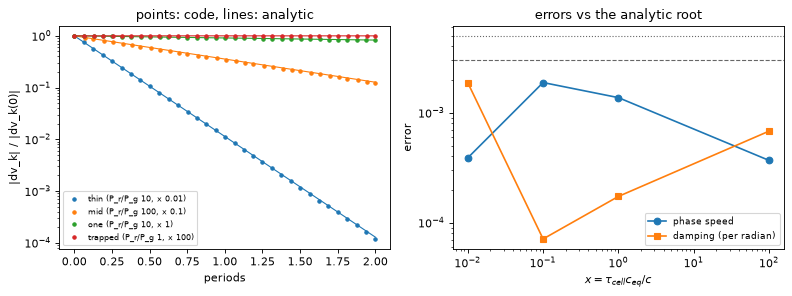

dt with / without rad_signal_speed_diff at x = 0.01: 2.771
PASS radwave   criterion {"max": {"err_cph": 0.003, "err_damp": 0.005}, "min": {"damp": 1e-06}, "near": {"dt_gain": [2.77, 0.02]}, "equal": {"warnings": 0}}


In [3]:
# the k = 1 amplitude of dv against the analytic decay, and the errors per regime
rt, vett = nb.rt, nb.vett
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
xs, cl, k = [], 1.0e3, 2*np.pi
for tag, prat, x, diff in rt.RADWAVE:
    if tag.endswith('_old'):
        continue
    d = os.path.join(WORK, TEST, tag)
    ceq = vett.radwave_root(prat, 1.0, cl)[3]
    w = vett.radwave_root(prat, x*cl*64/ceq, cl)[0]
    t, a = [], []
    for f in vett.bins(d, 'hydro_w'):
        h = vett.read_bin(f)
        t.append(h['time']); a.append(abs(2*np.mean(h['velx'].mean(axis=(0, 1))*np.exp(-1j*k*vett.cell_centres(d)[0]))))
    t, a = np.array(t), np.array(a)
    l, = ax[0].semilogy(t*w.real/(2*np.pi), a/a[0], 'o', ms=3, label='%s (P_r/P_g %g, x %g)' % (tag, prat, x))
    ax[0].semilogy(t*w.real/(2*np.pi), np.exp(w.imag*t), '-', c=l.get_color(), lw=1)
    xs.append(x)
ax[0].set(xlabel='periods', ylabel='|dv_k| / |dv_k(0)|', title='points: code, lines: analytic')
ax[0].legend(fontsize=7)
ax[1].loglog(xs, res['err_cph'], 'o-', label='phase speed')
ax[1].loglog(xs, res['err_damp'], 's-', label='damping (per radian)')
for b, ls in ((3e-3, '--'), (5e-3, ':')):
    ax[1].axhline(b, c='0.4', ls=ls, lw=1)
ax[1].set(xlabel=r'$x = \tau_{cell} c_{eq}/c$', ylabel='error', title='errors vs the analytic root')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('dt with / without rad_signal_speed_diff at x = 0.01: %.3f' % res['dt_gain'])
_ = nb.verdict(TEST, res)